In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# load merged dataset
final_df = pd.read_csv("../data/processed/final_combined_dataset.csv")

final_df.head()


,crop,year,season,state,area,production,fertilizer,pesticide,yield,n,p,k,soil_ph,avg_temp_c,total_rainfall_mm,avg_humidity_percent
0,arecanut,1997,whole year,assam,73814.0,56708,7024878.38,22882.34,0.80,60,18,38,5.8,22.41,1468.92,70.71
1,arhar/tur,1997,kharif,assam,6637.0,4685,631643.29,2057.47,0.71,60,18,38,5.8,22.41,1468.92,70.71
2,castor seed,1997,kharif,assam,796.0,22,75755.32,246.76,0.24,60,18,38,5.8,22.41,1468.92,70.71
3,coconut,1997,whole year,assam,19656.0,126905000,1870661.52,6093.36,5238.05,60,18,38,5.8,22.41,1468.92,70.71
4,cotton(lint),1997,kharif,assam,1739.0,794,165500.63,539.09,0.42,60,18,38,5.8,22.41,1468.92,70.71


In [2]:
final_df.shape


(19577, 16)

In [3]:
final_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 19577 entries, 0 to 19576
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   crop                  19577 non-null  str    
 1   year                  19577 non-null  int64  
 2   season                19577 non-null  str    
 3   state                 19577 non-null  str    
 4   area                  19577 non-null  float64
 5   production            19577 non-null  int64  
 6   fertilizer            19577 non-null  float64
 7   pesticide             19577 non-null  float64
 8   yield                 19577 non-null  float64
 9   n                     19577 non-null  int64  
 10  p                     19577 non-null  int64  
 11  k                     19577 non-null  int64  
 12  soil_ph               19577 non-null  float64
 13  avg_temp_c            19577 non-null  float64
 14  total_rainfall_mm     19577 non-null  float64
 15  avg_humidity_percent  19577 no

In [4]:
final_df.describe()


,year,area,production,fertilizer,pesticide,yield,n,p,k,soil_ph,avg_temp_c,total_rainfall_mm,avg_humidity_percent
count,19577.000000,1.957700e+04,1.957700e+04,1.957700e+04,1.957700e+04,19577.000000,19577.000000,19577.000000,19577.000000,19577.000000,19577.000000,19577.000000,19577.000000
mean,2009.117945,1.809265e+05,1.652997e+07,2.423721e+07,4.911903e+04,80.411429,76.570823,33.466261,32.234867,6.639480,23.995587,1338.309725,64.684968
std,6.499877,7.348001e+05,2.638053e+08,9.520033e+07,2.138658e+05,880.794277,20.013561,11.565382,7.895718,0.690156,4.415597,638.585760,11.466395
min,1997.000000,5.000000e-01,0.000000e+00,5.417000e+01,9.000000e-02,0.000000,50.000000,15.000000,20.000000,5.500000,6.260000,249.240000,34.470000
25%,2004.000000,1.439000e+03,1.448000e+03,1.935634e+05,3.696300e+02,0.600000,65.000000,24.000000,25.000000,6.000000,22.890000,894.160000,54.620000
50%,2010.000000,9.501000e+03,1.408200e+04,1.258710e+06,2.473450e+03,1.040000,72.000000,38.000000,33.000000,6.600000,25.540000,1172.020000,68.110000
75%,2015.000000,7.599300e+04,1.244600e+05,1.013409e+07,2.021619e+04,2.410000,80.000000,43.000000,38.000000,7.100000,26.800000,1613.400000,73.730000
max,2020.000000,5.080810e+07,6.326000e+09,4.835407e+09,1.575051e+07,21105.000000,150.000000,55.000000,50.000000,8.000000,28.630000,5244.360000,86.060000


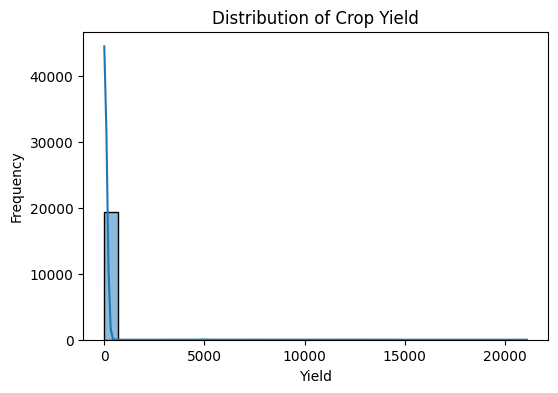

In [5]:
plt.figure(figsize=(6,4))
sns.histplot(final_df["yield"], bins=30, kde=True)
plt.title("Distribution of Crop Yield")
plt.xlabel("Yield")
plt.ylabel("Frequency")
plt.show()


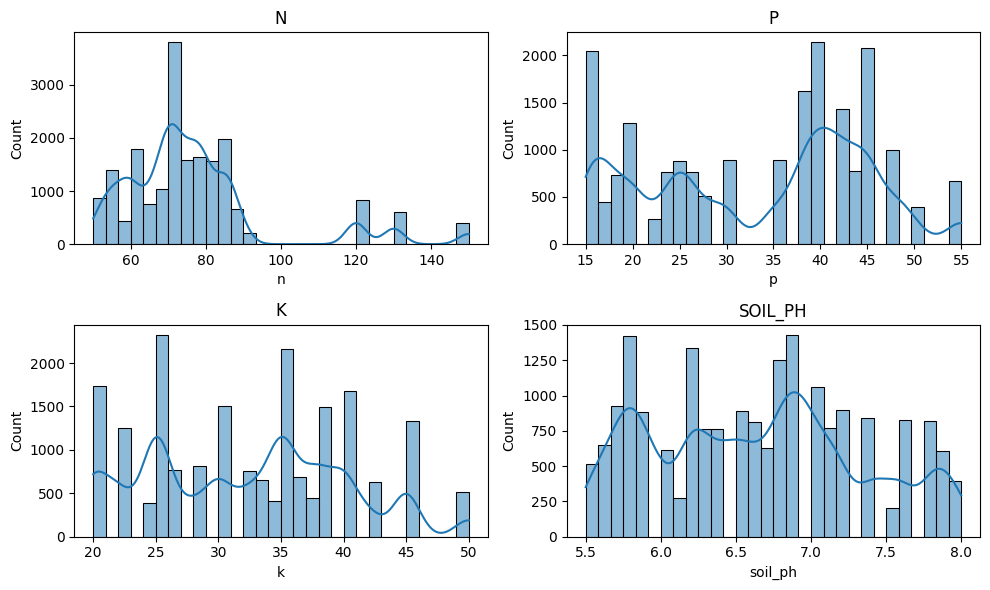

In [6]:
features = ["n", "p", "k", "soil_ph"]

plt.figure(figsize=(10,6))
for i, col in enumerate(features, 1):
    plt.subplot(2, 2, i)
    sns.histplot(final_df[col], bins=30, kde=True)
    plt.title(col.upper())

plt.tight_layout()
plt.show()


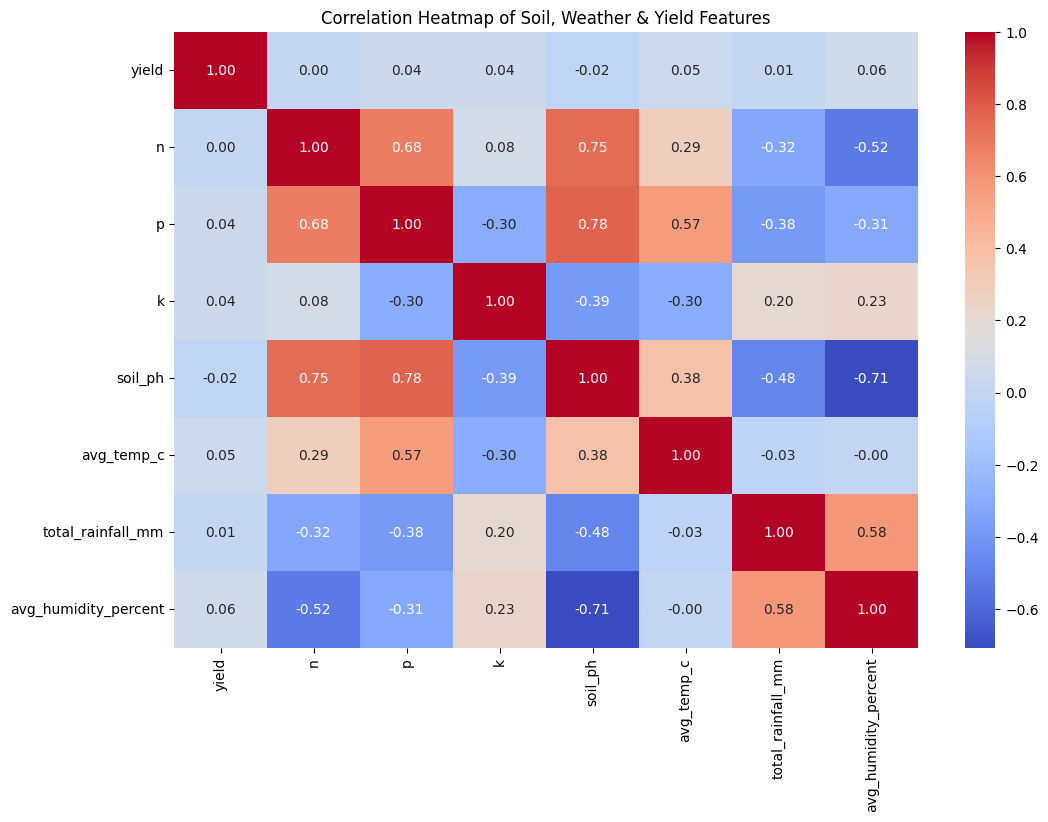

In [7]:
plt.figure(figsize=(12,8))

corr = final_df[
    ["yield", "n", "p", "k", "soil_ph",
     "avg_temp_c", "total_rainfall_mm", "avg_humidity_percent"]
].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Soil, Weather & Yield Features")
plt.show()


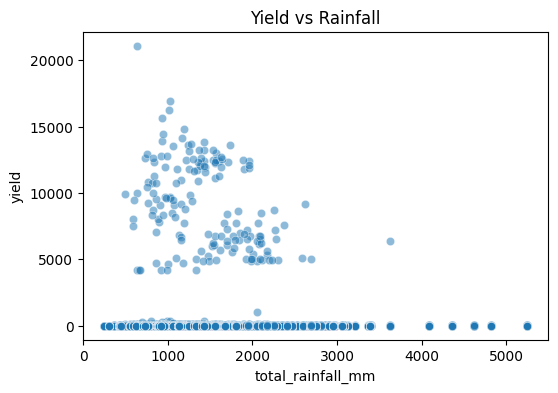

In [8]:
plt.figure(figsize=(6,4))
sns.scatterplot(
    x="total_rainfall_mm",
    y="yield",
    data=final_df,
    alpha=0.5
)
plt.title("Yield vs Rainfall")
plt.show()


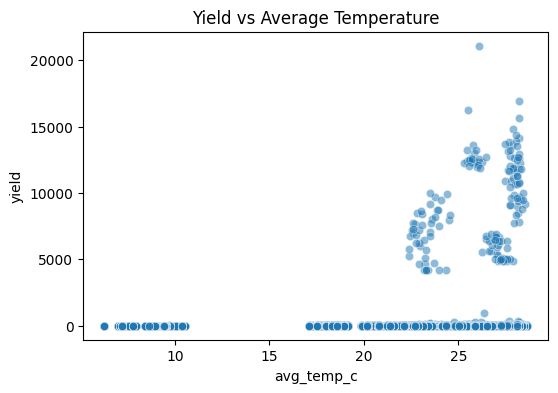

In [9]:
plt.figure(figsize=(6,4))
sns.scatterplot(
    x="avg_temp_c",
    y="yield",
    data=final_df,
    alpha=0.5
)
plt.title("Yield vs Average Temperature")
plt.show()


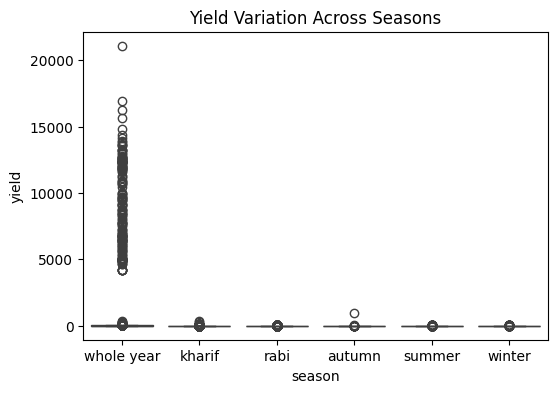

In [10]:
plt.figure(figsize=(6,4))
sns.boxplot(x="season", y="yield", data=final_df)
plt.title("Yield Variation Across Seasons")
plt.show()


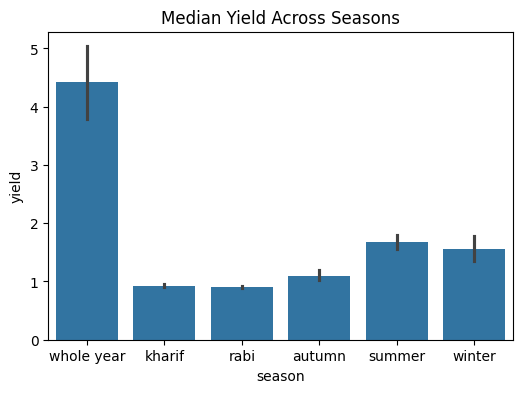

In [11]:
plt.figure(figsize=(6,4))
sns.barplot(
    x="season",
    y="yield",
    data=final_df,
    estimator="median"
)
plt.title("Median Yield Across Seasons")
plt.show()
